# 1.0 IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2.0 Load Data

In [2]:
df = pd.read_csv("Applications_Compiled.csv")

print("Original dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Original dataset shape: (2199861, 11)

Columns:
['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs', 'Type', 'Price', 'ContentRating', 'LastUpdated', 'MinAndroidVer']


# 3.0 Clean Numeric Columns

In [3]:
numeric_raw_columns = [
    "Rating",
    "ReviewCount",
    "Size_MB",
    "Price",
    "Installs"
]

for col in numeric_raw_columns:
    # Handles numeric values stored as strings with commas or symbols
    df[col] = pd.to_numeric(
        df[col].astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"[^\d.\-]", "", regex=True),
        errors="coerce"
    )

# Negative values are invalid for these fields
for col in numeric_raw_columns:
    df.loc[df[col] < 0, col] = np.nan

# The target must be present and nonnegative
df = df.dropna(subset=["Installs"]).copy()

print("\nDataset shape after cleaning:", df.shape)
print("\nInstall count summary:")
print(df["Installs"].describe())


Dataset shape after cleaning: (2199861, 11)

Install count summary:
count         2199861.0
mean      119007.871083
std      3903970.455894
min                 0.0
25%                50.0
50%               500.0
75%              5000.0
max        1000000000.0
Name: Installs, dtype: Float64


# 4. Prepare Features and Target

In [4]:
# Parse dates
df["LastUpdated"] = pd.to_datetime(
    df["LastUpdated"],
    errors="coerce"
)

# Use today's date as the reference for days since update
reference_date = pd.Timestamp.today().normalize()

df["Days_Since_Update"] = (
    reference_date - df["LastUpdated"]
).dt.days

# Additional date features
df["Update_Year"] = df["LastUpdated"].dt.year
df["Update_DayOfWeek"] = df["LastUpdated"].dt.dayofweek
df["Is_Weekend"] = (
    df["Update_DayOfWeek"] >= 5
).astype("float")

# Encode month cyclically so December and January are close
month = df["LastUpdated"].dt.month

df["Month_Sin"] = np.sin(2 * np.pi * month / 12)
df["Month_Cos"] = np.cos(2 * np.pi * month / 12)

# Log-transform review counts
# Also identify apps with no reviews

df["Has_Reviews"] = (
    df["ReviewCount"].fillna(0) > 0
).astype(int)

df["ReviewCount"] = np.log1p(df["ReviewCount"])

# Define features
numeric_features = [
    "Rating",
    "ReviewCount",
    "Has_Reviews",
    "Size_MB",
    "Price",
    "Days_Since_Update",
    "Update_Year",
    "Update_DayOfWeek",
    "Is_Weekend",
    "Month_Sin",
    "Month_Cos"
]

categorical_features = [
    "Category",
    "Type",
    "ContentRating",
    "MinAndroidVer"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df["Installs"].copy()

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nMissing target values:", y.isna().sum())


Feature matrix shape: (2199861, 15)
Target shape: (2199861,)

Missing target values: 0


# 5. Train / Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 1759888
Testing rows: 439973


# 6. Preprocessing Pipelines

In [6]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 7. Build Ridge Regression Pipeline

In [7]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# 8. Log-Transform The Target

In [8]:
y_train_log = np.log1p(y_train)

# 9. Hyperparatmeter Tuning

In [9]:
param_grid = {
    "regressor__alpha": [0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=1,
    refit=True,
    verbose=2
)

grid_search.fit(X_train, y_train_log)

best_model = grid_search.best_estimator_

print("\nBest alpha:", grid_search.best_params_)
print("Best CV RMSE on log scale:",
      -grid_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ...............................regressor__alpha=0.1; total time=  19.0s
[CV] END ...............................regressor__alpha=0.1; total time=  19.6s
[CV] END ...............................regressor__alpha=0.1; total time=  12.8s
[CV] END .................................regressor__alpha=1; total time=  24.7s
[CV] END .................................regressor__alpha=1; total time=  20.4s
[CV] END .................................regressor__alpha=1; total time=  18.3s
[CV] END ................................regressor__alpha=10; total time=  24.4s
[CV] END ................................regressor__alpha=10; total time=  24.6s
[CV] END ................................regressor__alpha=10; total time=  16.5s
[CV] END ...............................regressor__alpha=100; total time=  12.6s
[CV] END ...............................regressor__alpha=100; total time=  24.1s
[CV] END ...............................regressor

# 10. Generate Predictions

In [10]:
y_pred_log = np.asarray(
    best_model.predict(X_test),
    dtype=float
)

y_test_numeric = np.asarray(y_test, dtype=float)

print("\nPREDICTIONS ON LOG SCALE")
print("Minimum:", np.min(y_pred_log))
print("Median:", np.median(y_pred_log))
print("Maximum:", np.max(y_pred_log))

print(
    "Non-finite predictions:",
    (~np.isfinite(y_pred_log)).sum()
)

# Stop if predictions are invalid or unsafe to exponentiate
if not np.isfinite(y_pred_log).all():
    raise ValueError(
        "Non-finite predictions detected. Inspect the pipeline."
    )

if np.max(y_pred_log) > 700:
    raise ValueError(
        "Predicted log installs are too large. "
        "Inspect the feature transformations before evaluation."
    )

# Convert predictions back to the original install scale
y_pred = np.expm1(y_pred_log)

# Installs cannot be negative
y_pred = np.maximum(y_pred, 0)

print("\nPREDICTIONS ON ORIGINAL SCALE")
print("Minimum:", np.min(y_pred))
print("Median:", np.median(y_pred))
print("Maximum:", np.max(y_pred))

print("\nACTUAL INSTALL COUNTS")
print("Minimum:", np.min(y_test_numeric))
print("Median:", np.median(y_test_numeric))
print("Maximum:", np.max(y_test_numeric))


PREDICTIONS ON LOG SCALE
Minimum: 0.3093604174282758
Median: 5.514595716075961
Maximum: 21.246702981413776
Non-finite predictions: 0

PREDICTIONS ON ORIGINAL SCALE
Minimum: 0.3625533699972224
Median: 247.2895774691568
Maximum: 1687818967.8277204

ACTUAL INSTALL COUNTS
Minimum: 0.0
Median: 500.0
Maximum: 500000000.0


# 11. Evaluate Model Performance

In [11]:
# Metrics on the original install scale
mae = mean_absolute_error(y_test_numeric, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test_numeric, y_pred)
)

r2 = r2_score(y_test_numeric, y_pred)

# Metrics on the log scale, useful for this highly skewed target
log_mae = mean_absolute_error(y_test_numeric, y_pred)
log_mae = mean_absolute_error(
    np.log1p(y_test_numeric),
    y_pred_log
)

log_rmse = np.sqrt(
    mean_squared_error(
        np.log1p(y_test_numeric),
        y_pred_log
    )
)

print("\nMODEL EVALUATION")
print("MAE (installs):", mae)
print("RMSE (installs):", rmse)
print("R-squared (installs):", r2)
print("MAE (log scale):", log_mae)
print("RMSE (log scale):", log_rmse)


MODEL EVALUATION
MAE (installs): 110658.08419821938
RMSE (installs): 4813713.634664226
R-squared (installs): -2.117520305557525
MAE (log scale): 1.1756934128355012
RMSE (log scale): 1.516872782564572


# 12. Inspect Largest Predictions

In [12]:
top_positions = np.argsort(y_pred_log)[-10:][::-1]

prediction_check = pd.DataFrame({
    "Actual_Installs": y_test_numeric[top_positions],
    "Predicted_Installs": y_pred[top_positions],
    "Predicted_Log_Installs": y_pred_log[top_positions]
})

print("\nTOP 10 PREDICTIONS")
display(prediction_check)

print("\nMAXIMUM PREDICTED INSTALLS:")
print(np.max(y_pred))

print("\nMAXIMUM ACTUAL INSTALLS:")
print(np.max(y_test_numeric))


TOP 10 PREDICTIONS


,Actual_Installs,Predicted_Installs,Predicted_Log_Installs
0,100000000.0,1.687819e+09,21.246703
1,500000000.0,1.337643e+09,21.014175
2,100000000.0,1.223816e+09,20.925239
3,100000000.0,1.214553e+09,20.917642
4,100000000.0,1.014926e+09,20.738082
5,500000000.0,9.759028e+08,20.698874
6,500000000.0,8.430554e+08,20.552543
7,100000000.0,6.677060e+08,20.319358
8,100000000.0,6.318601e+08,20.264179
9,100000000.0,6.032239e+08,20.217799



MAXIMUM PREDICTED INSTALLS:
1687818967.8277204

MAXIMUM ACTUAL INSTALLS:
500000000.0


# 13. Visualizations

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

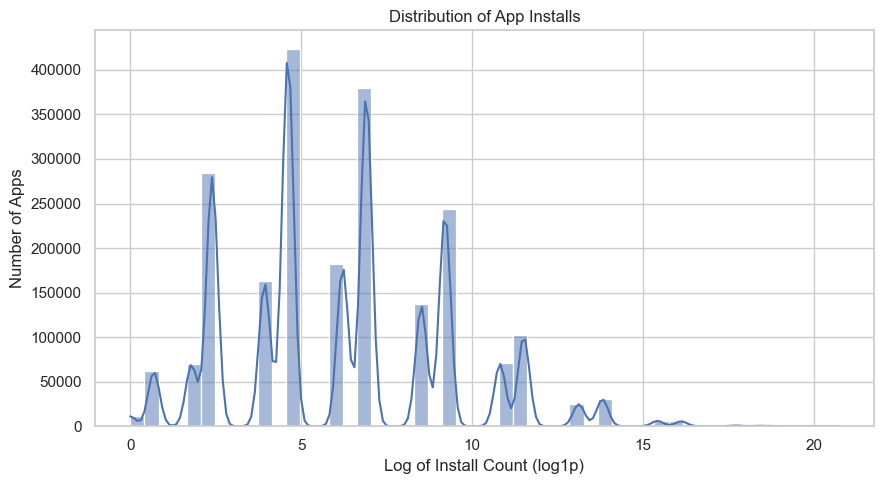

In [24]:
# Visualization 1: Distribution of App Installs

plt.figure(figsize=(9, 5))

sns.histplot(
    np.log1p(df["Installs"].dropna()),
    bins=50,
    kde=True
)

plt.title("Distribution of App Installs")
plt.xlabel("Log of Install Count (log1p)")
plt.ylabel("Number of Apps")

plt.tight_layout()
plt.show()

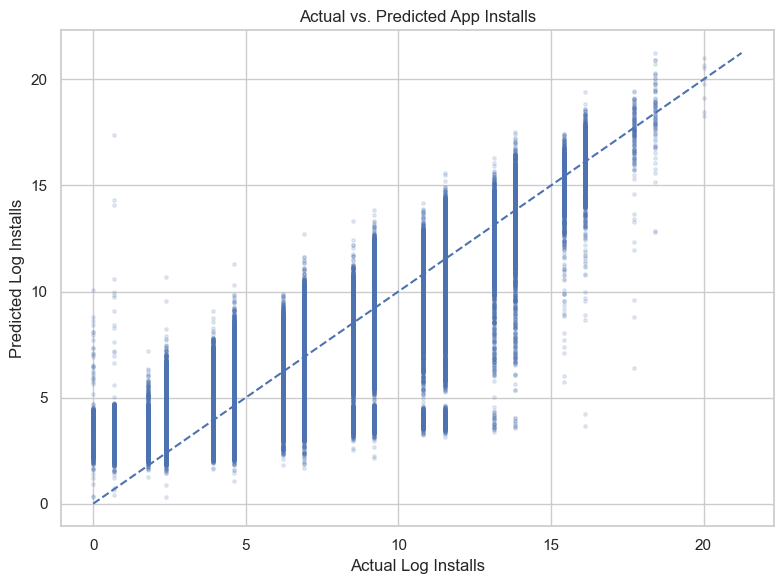

In [25]:
# Visualization 2: Actual vs. Predicted Installs

actual_log = np.log1p(y_test_numeric)
predicted_log = y_pred_log

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_log,
    predicted_log,
    alpha=0.15,
    s=6
)

lower = min(actual_log.min(), predicted_log.min())
upper = max(actual_log.max(), predicted_log.max())

# Reference line for perfect predictions
plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.title("Actual vs. Predicted App Installs")
plt.xlabel("Actual Log Installs")
plt.ylabel("Predicted Log Installs")

plt.tight_layout()
plt.show()

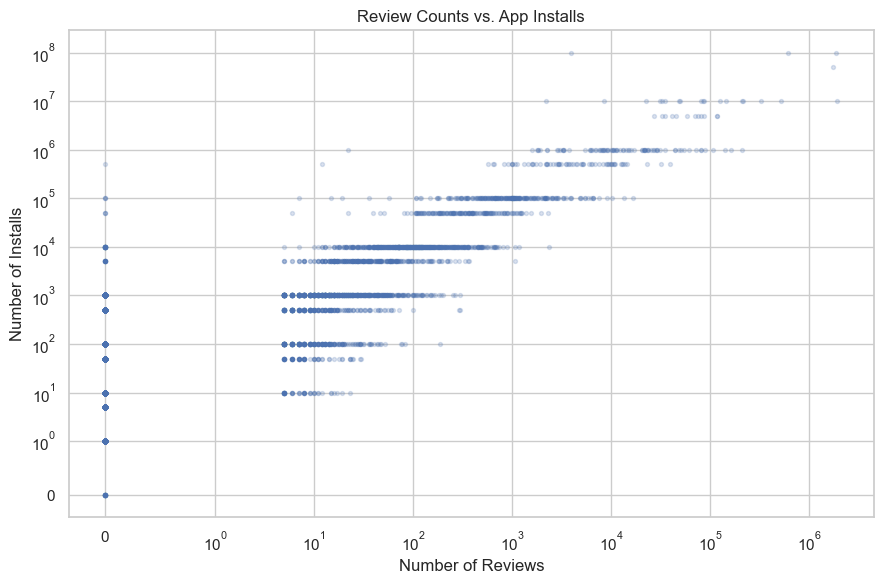

In [26]:
# Visualization 3: Review Counts vs. Installs

review_plot_df = df[
    ["ReviewCount", "Installs"]
].copy()

# ReviewCount was log-transformed during model preparation.
# Convert it back to its original scale for this chart.
review_plot_df["ReviewCount"] = np.expm1(
    review_plot_df["ReviewCount"]
)

# Sample records to keep the chart readable
review_plot_df = review_plot_df.sample(
    n=min(5000, len(review_plot_df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

plt.scatter(
    review_plot_df["ReviewCount"],
    review_plot_df["Installs"],
    alpha=0.2,
    s=8
)

plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)

plt.title("Review Counts vs. App Installs")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Installs")

plt.tight_layout()
plt.show()